<a href="https://colab.research.google.com/github/paggalih/research/blob/main/bioinformatics/pancreas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install scanpy scvelo cellrank --quiet
!pip install -U scvelo --quiet
!pip install "numpy<2.3" --quiet
!pip install "pandas<3" --quiet
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd

# Patch: scVelo passes lists to pd.unique
_orig_unique = pd.unique
def _safe_unique(values):
    if isinstance(values, (list, tuple)):
        values = np.asarray(values, dtype=object)
    return _orig_unique(values)
pd.unique = _safe_unique

import scanpy as sc
import scvelo as scv
scv.settings.verbosity = 1

import numba

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.


AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: 'spliced', 'unspliced', None (.X)
clusters
Ductal           916
Ngn3 high EP     642
Pre-endocrine    592
Beta             591
Alpha            481
Ngn3 low EP      262
Epsilon          142
Delta             70
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


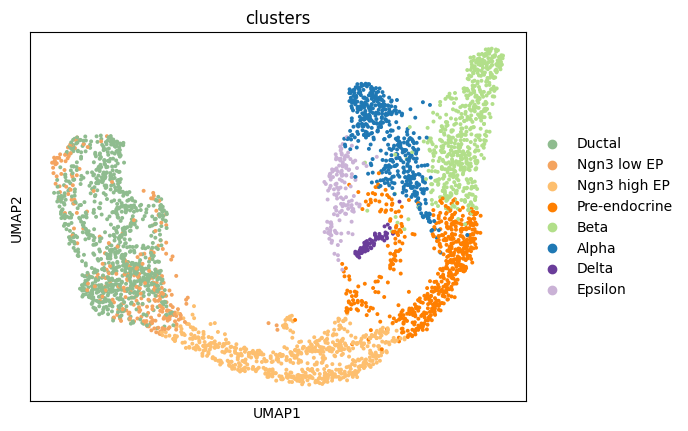

AnnData object with n_obs × n_vars = 3696 × 2000
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts'
    var: 'highly_variable_genes', 'gene_count_corr', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca', 'log1p', 'hvg', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: 'spliced', 'unspliced', None (.X), 'Ms', 'Mu'


In [2]:
adata = scv.datasets.pancreas()
print(adata)
print(adata.obs["clusters"].value_counts())

scv.pp.filter_and_normalize(adata, min_shared_counts=20)

if "log1p" not in adata.uns:
    sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True)

sc.tl.pca(adata)
sc.pp.neighbors(adata, n_pcs=30, n_neighbors=30)
scv.pp.moments(adata)

sc.tl.umap(adata)
sc.pl.umap(adata, color="clusters", save="_clusters.png")
print(adata)

/usr/local/lib/python3.13/dist-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/

  0%|          | 0/3696 [00:00<?, ?cells/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=21719) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a futu

saving figure to file ./figures/scvelo_velocity_stochastic.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


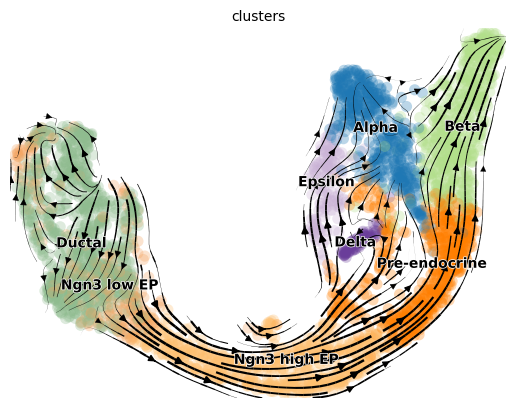

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/1036 [00:00<?, ?gene/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=21719) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/3696 [00:00<?, ?cells/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=21719) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a futu

saving figure to file ./figures/scvelo_velocity_dynamical.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


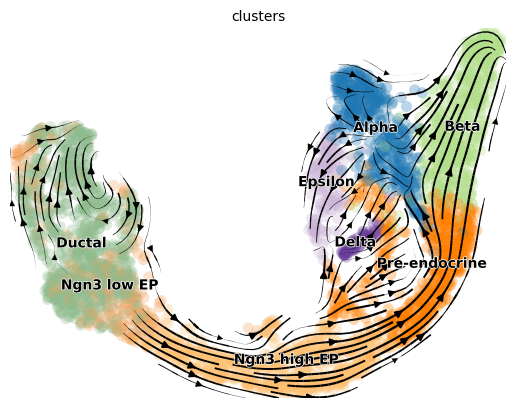

saving figure to file ./figures/scvelo_latent_time.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


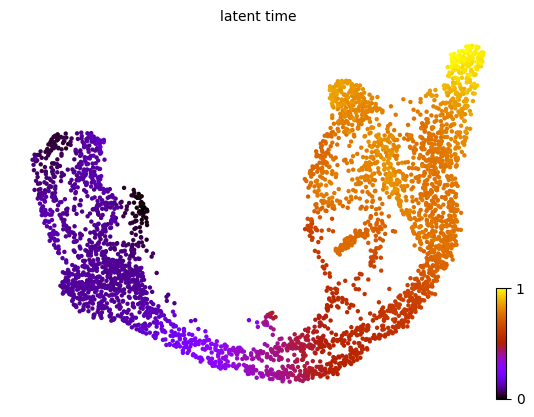

saving figure to file ./figures/scvelo_phase_portraits.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


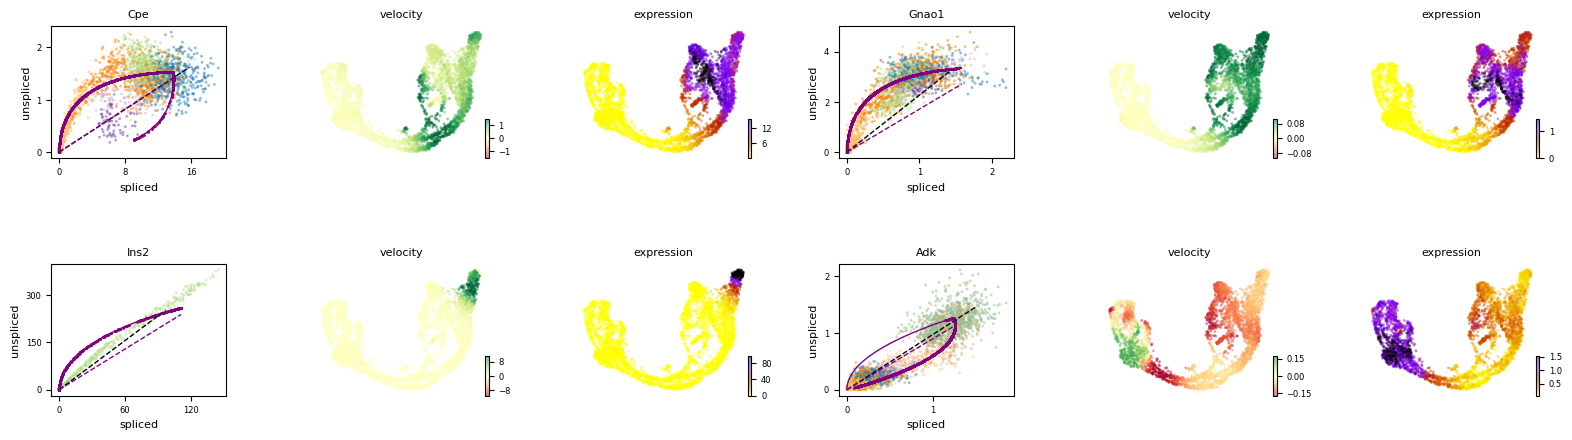

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
# 1. Fast model first
scv.tl.velocity(adata, mode="stochastic")
scv.tl.velocity_graph(adata)
scv.pl.velocity_embedding_stream(
    adata, basis="umap", color="clusters",
    save="velocity_stochastic.png"
)

# 2. Dynamical model (slower, ~5–10 min)
scv.tl.recover_dynamics(adata, n_jobs=2)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata)
scv.pl.velocity_embedding_stream(
    adata, basis="umap", color="clusters",
    save="velocity_dynamical.png"
)
# 3. Latent time
scv.tl.latent_time(adata)
scv.pl.scatter(
    adata, color="latent_time", color_map="gnuplot",
    size=40, save="latent_time.png"
)
# 4. Phase portraits: u vs s per gene
scv.pl.velocity(
    adata, ["Cpe", "Gnao1", "Ins2", "Adk"],
    ncols=2, save="phase_portraits.png"
)
# 5. Save progress
adata.write("pancreas_velocity.h5ad")

INFO     Computing transition matrix using 'deterministic' model                                                   


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/3696 [00:00<?, ?cell/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=21719) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a futu

INFO     Using `softmax_scale=4.9780`                                                                              


  0%|          | 0/3696 [00:00<?, ?cell/s]

... (15 outputs left out)

INFO     Adding `adata.obsm['lineages_fwd']`                                                                       
                `.fate_probabilities`                                                                              
             Finish (0.39s)                                                                                        
INFO     Adding `adata.varm['terminal_lineage_drivers']`                                                           
                `.lineage_drivers`                                                                                 
             Finish (0.12s)                                                                                        
          Alpha_corr    Alpha_pval    Alpha_qval  Alpha_ci_low  Alpha_ci_high  \
index                                                                           
Hnrnpa1    -0.290112  1.253782e-73  1.003026e-71     -0.319366      -0.260306   
Cd24a      -0.291430  2.539904e-74  2.116586e-72     -0.32065

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


INFO     Adding `.macrostates`                                                                                     
                `.macrostates_memberships`                                                                         
                `.coarse_T`                                                                                        
                `.coarse_initial_distribution                                                                      
                `.coarse_stationary_distribution`                                                                  
                `.schur_vectors`                                                                                   
                `.schur_matrix`                                                                                    
                `.eigendecomposition`                                                                              
             Finish (2.19s)                                             

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expre

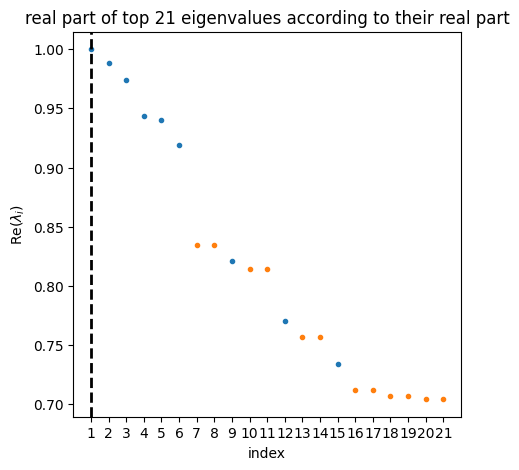

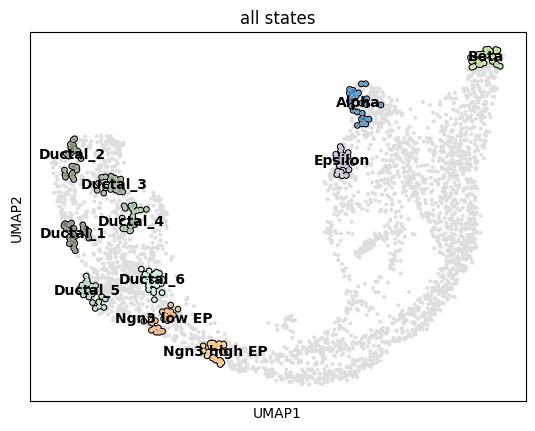

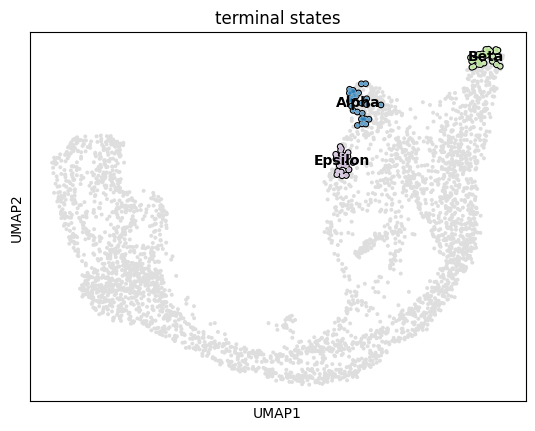

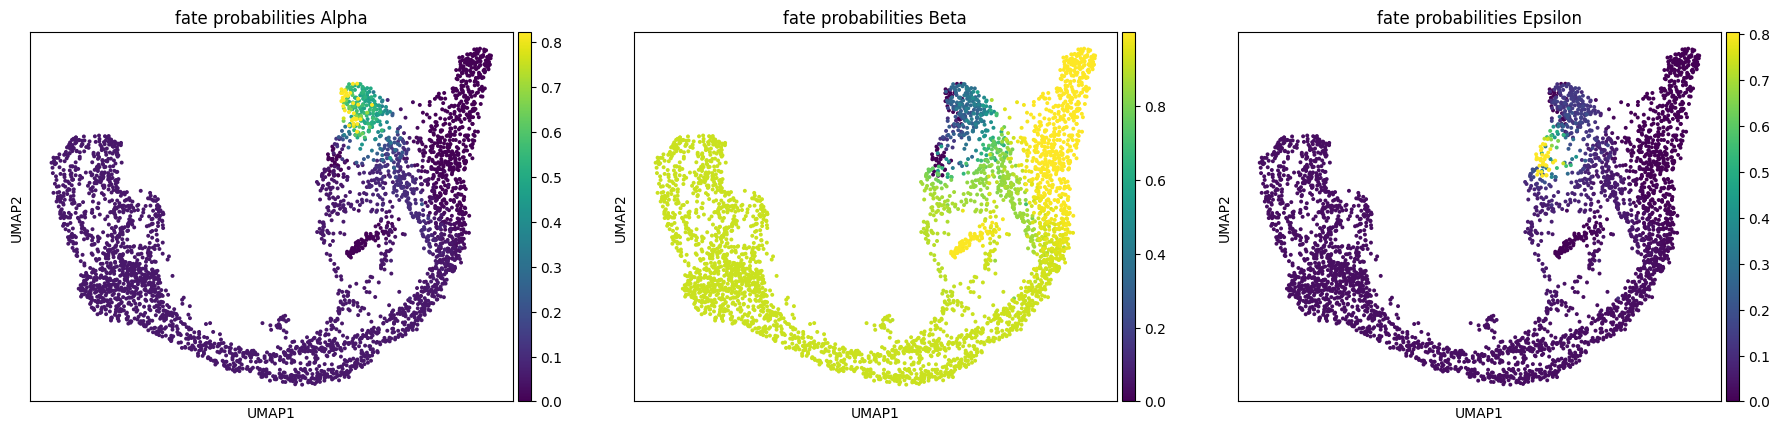

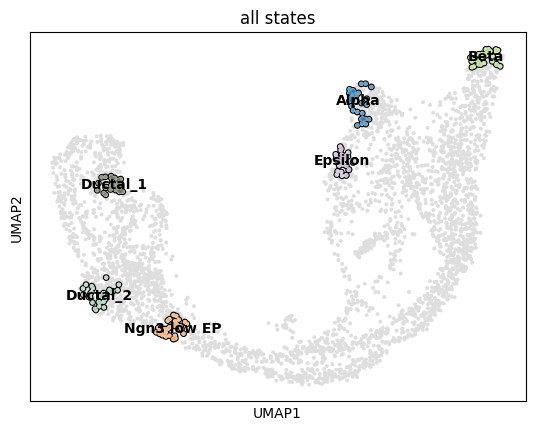

In [4]:
import cellrank as cr

# 1. Build transition matrix
vk = cr.kernels.VelocityKernel(adata).compute_transition_matrix()
ck = cr.kernels.ConnectivityKernel(adata).compute_transition_matrix()
kernel = 0.8 * vk + 0.2 * ck
print(kernel)

# 2. Estimator + spectrum
g = cr.estimators.GPCCA(kernel)
g.compute_schur(n_components=20)
g.plot_spectrum(real_only=True, save="spectrum.png")

# 3. Macrostates
g.compute_macrostates(n_states=10, cluster_key="clusters")
g.plot_macrostates(which="all", save="macrostates.png")

# 4. Terminal states
g.set_terminal_states(states=["Alpha", "Beta", "Epsilon"])
g.plot_macrostates(which="terminal", save="terminal_fixed.png")


# 5. Fate probabilities
g.compute_fate_probabilities()
g.plot_fate_probabilities(same_plot=False, save="fates_fixed.png")

# 6. Driver genes for Beta
drivers = g.compute_lineage_drivers(cluster_key="clusters")
print(drivers.sort_values("Beta_corr", ascending=False).head(10))

g.compute_macrostates(n_states=6, cluster_key="clusters")
g.plot_macrostates(which="all", save="macrostates_6.png")

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
_orig_unique = pd.unique
def _safe_unique(v):
    if isinstance(v, (list, tuple)):
        v = np.asarray(v, dtype=object)
    return _orig_unique(v)
pd.unique = _safe_unique

import scanpy as sc, scvelo as scv
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.sparse import issparse

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

# Upload pancreas_velocity.h5ad first
adata = sc.read("pancreas_velocity.h5ad")

cpu


In [6]:
X = adata.X.toarray() if issparse(adata.X) else adata.X
X = torch.tensor(X, dtype=torch.float32)
print(X.shape)   # expect (3696, 2000)

loader = torch.utils.data.DataLoader(X, batch_size=128, shuffle=True)

torch.Size([3696, 2000])


In [7]:
class VAE(nn.Module):
    def __init__(self, n_genes, n_latent=10, n_hidden=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_genes, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
        )
        self.mu = nn.Linear(n_hidden, n_latent)
        self.logvar = nn.Linear(n_hidden, n_latent)
        self.decoder = nn.Sequential(
            nn.Linear(n_latent, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_genes),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    recon = F.mse_loss(x_hat, x, reduction="sum") / x.shape[0]
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.shape[0]
    return recon + beta * kl, recon, kl

In [8]:
model = VAE(n_genes=X.shape[1]).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

history = []
for epoch in range(100):
    model.train()
    tot, rec, kld = 0.0, 0.0, 0.0
    for xb in loader:
        xb = xb.to(device)
        x_hat, mu, logvar = model(xb)
        loss, r, k = vae_loss(x_hat, xb, mu, logvar)
        opt.zero_grad()
        loss.backward()
        opt.step()
        n = xb.shape[0]
        tot += loss.item() * n; rec += r.item() * n; kld += k.item() * n
    N = len(loader.dataset)
    history.append((tot / N, rec / N, kld / N))
    if epoch % 10 == 0:
        print(f"epoch {epoch:3d} | loss {tot/N:.1f} | recon {rec/N:.1f} | KL {kld/N:.2f}")

torch.save(model.state_dict(), "vae.pt")

epoch   0 | loss 453.5 | recon 445.6 | KL 7.87
epoch  10 | loss 231.8 | recon 225.6 | KL 6.22
epoch  20 | loss 221.7 | recon 215.6 | KL 6.13
epoch  30 | loss 218.3 | recon 212.1 | KL 6.18
epoch  40 | loss 216.2 | recon 210.0 | KL 6.25
epoch  50 | loss 214.5 | recon 208.2 | KL 6.28
epoch  60 | loss 213.6 | recon 207.2 | KL 6.36
epoch  70 | loss 212.5 | recon 206.1 | KL 6.37
epoch  80 | loss 211.6 | recon 205.2 | KL 6.42
epoch  90 | loss 211.1 | recon 204.6 | KL 6.45


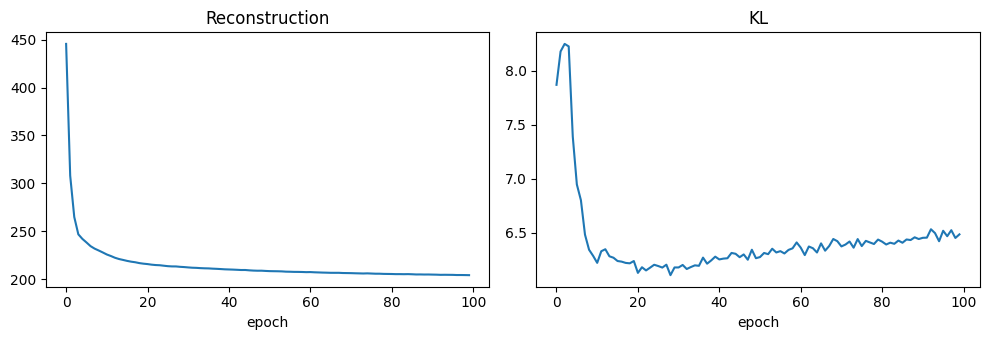

In [9]:
import matplotlib.pyplot as plt
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h[:, 1]); ax[0].set_title("Reconstruction"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 2]); ax[1].set_title("KL"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("figures/vae_loss.png", dpi=150); plt.show()

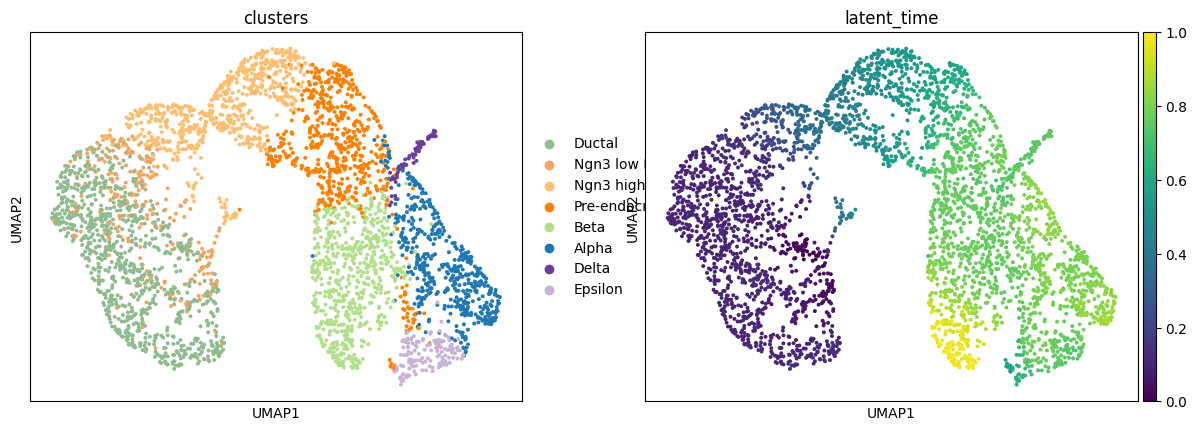

In [10]:
model.eval()
with torch.no_grad():
    mu, _ = model.encode(X.to(device))

ad_vae = adata.copy()   # keep velocity graph untouched
ad_vae.obsm["X_vae"] = mu.cpu().numpy()
sc.pp.neighbors(ad_vae, use_rep="X_vae", n_neighbors=30)
sc.tl.umap(ad_vae)
sc.pl.umap(ad_vae, color=["clusters", "latent_time"],
           save="_vae_latent.png")